In [44]:
import pandas as pd
import numpy as np

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,id,A,B,C,Y
0,train_0000,1.0000,1.0,10.0,11.5660
1,train_0001,1.1864,1.0,10.0,11.5963
2,train_0002,1.3729,1.0,10.0,12.6069
3,train_0003,1.5593,1.0,10.0,12.5776
4,train_0004,1.7458,1.0,10.0,12.9773


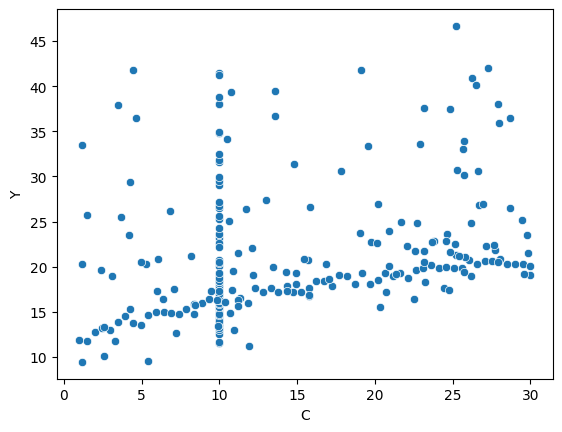

In [45]:
import matplotlib.pyplot as plt # ne uitam la relatii intre variabile gen
import seaborn as sns

sns.scatterplot(x=df_train.C, y=df_train.Y)
plt.show()

In [47]:
feats = ["A", "B", "C"]
target = 'Y'

X = df_train[feats]
y = df_train[target]
X_final = df_test[feats]

def make_feats(X):
    X = X.copy()
    for c in ["A", "C"]:
        X[c + "_sqrt"] = np.sqrt(X[c])
        X[c + "_log"]  = np.log(X[c])
        X[c + "_sq"]   = X[c] ** 2
    X["B_sq"]  = X["B"] ** 2
    X["B_exp"] = np.exp(X["B"])
    X["AB"] = X["A"] * X["B"]
    X["AC"] = X["A"] * X["C"]
    X["BC"] = X["B"] * X["C"]
    return X

X = make_feats(X)
X_final = make_feats(X_final)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)
X_final = pd.DataFrame(scaler.transform(X_final), columns=X_final.columns)

X.head()

,A,B,C,A_sqrt,A_log,A_sq,C_sqrt,C_log,C_sq,B_sq,B_exp,AB,AC,BC
0,-1.919877,-0.459177,-0.521186,-2.565883,-3.412938,-1.156292,-0.419158,-0.255782,-0.59576,-0.544393,-0.513556,-1.208229,-1.124574,-0.553603
1,-1.847095,-0.459177,-0.521186,-2.399136,-3.064077,-1.144677,-0.419158,-0.255782,-0.59576,-0.544393,-0.513556,-1.175056,-1.096398,-0.553603
2,-1.774275,-0.459177,-0.521186,-2.244970,-2.766083,-1.131073,-0.419158,-0.255782,-0.59576,-0.544393,-0.513556,-1.141866,-1.068208,-0.553603
3,-1.701493,-0.459177,-0.521186,-2.101040,-2.506235,-1.115495,-0.419158,-0.255782,-0.59576,-0.544393,-0.513556,-1.108693,-1.040032,-0.553603
4,-1.628672,-0.459177,-0.521186,-1.965415,-2.275647,-1.097926,-0.419158,-0.255782,-0.59576,-0.544393,-0.513556,-1.075503,-1.011841,-0.553603


In [61]:
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

model = RidgeCV()

cross_val_score(model, X, y, cv=3, scoring='r2').mean()

np.float64(0.9831399098116367)

In [62]:
model.fit(X, y)
y_preds = model.predict(X_final)

In [63]:
submission = pd.DataFrame({
    "subtask_id": 1,
    "test_id": df_test['id'],
    "answer": y_preds
})

submission

,subtask_id,test_id,answer
0,1,test_0000,42.052821
1,1,test_0001,53.756678
2,1,test_0002,66.810635
3,1,test_0003,21.058226
4,1,test_0004,22.607412
...,...,...,...
165,1,test_0165,22.665850
166,1,test_0166,82.853096
167,1,test_0167,24.176973
168,1,test_0168,12.444373


In [64]:
submission.to_csv("submission.csv", index=False)